# 03 — Check a downloaded light curve

A quick check that `scripts/download_kepler.py` saved sensible data. We plot one star's light curve in three ways:
1. **The whole thing:** about 4 years of brightness measurements.
2. **A zoom on a few days,** with the expected dip times marked.
3. **Folded:** every orbit stacked on top of each other, so the dips line up into one clear dip.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BLUE = "#2a78d6"   # data
INK = "#52514e"    # markers and reference lines
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "grid.color": "#e6e5e1", "figure.dpi": 110})

KEPID = 6849046   # change this to look at another star (any file in data/kepler_raw/)

selected = pd.read_csv("../data/kepler_selected.csv")
koi = selected[selected["kepid"] == KEPID].iloc[0]
lc = pd.read_csv(f"../data/kepler_raw/{KEPID}.csv")

print(koi[["kepoi_name", "koi_disposition", "koi_period", "koi_time0bk", "koi_duration", "koi_depth"]])
print()
print(f"{len(lc):,} points, from day {lc.time.min():.0f} to day {lc.time.max():.0f}")
lc.head()

kepoi_name          K00201.01
koi_disposition     CONFIRMED
koi_period           4.225385
koi_time0bk        137.560689
koi_duration          2.82038
koi_depth              7563.0
Name: 228, dtype: object

64,792 points, from day 132 to day 1591


,time,flux,flux_err
0,131.512679,0.999839,0.000155
1,131.533114,1.000077,0.000155
2,131.553548,0.999953,0.000155
3,131.573982,0.999775,0.000155
4,131.594417,0.999804,0.000155


## 1. The whole light curve

- Each dot is one brightness measurement, taken every ~30 minutes.
- The flux is normalised, so 1.0 = the star's normal brightness.
- Gaps are normal: Kepler paused every ~3 months to send data back to Earth.
- The dips are so short compared with 4 years that they look like thin downward spikes here.

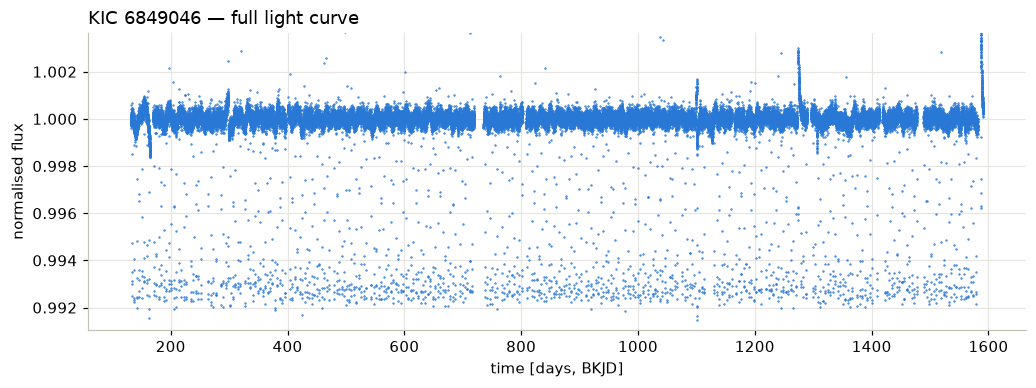

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(lc.time, lc.flux, ".", ms=1, color=BLUE)
lo, hi = np.percentile(lc.flux, [0.05, 99.9])   # ignore a few extreme outliers when choosing the y-range
pad = 0.1 * (hi - lo)
ax.set_ylim(lo - pad, hi + pad)
ax.set_title(f"KIC {KEPID} — full light curve", loc="left")
ax.set_xlabel("time [days, BKJD]")
ax.set_ylabel("normalised flux")
ax.grid(True)
plt.show()

## 2. Zoom in on a few orbits

- The grey dashed lines show where dips **should** be, from `koi_time0bk` + multiples of `koi_period`.
- If the data is right, the dips should line up with the lines.

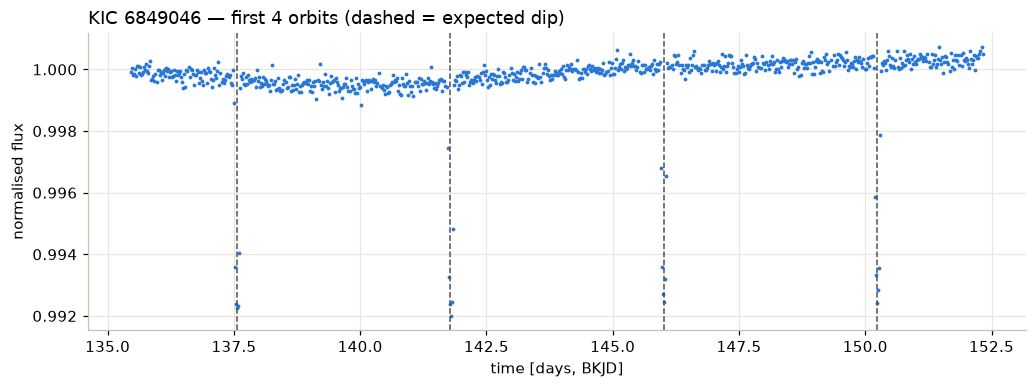

In [3]:
P, t0 = koi["koi_period"], koi["koi_time0bk"]
start = t0 - 0.5 * P
window = lc[(lc.time > start) & (lc.time < start + 4 * P)]

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(window.time, window.flux, ".", ms=3, color=BLUE)
for n in range(4):
    ax.axvline(t0 + n * P, color=INK, ls="--", lw=1)
ax.set_title(f"KIC {KEPID} — first 4 orbits (dashed = expected dip)", loc="left")
ax.set_xlabel("time [days, BKJD]")
ax.set_ylabel("normalised flux")
ax.grid(True)
plt.show()

## 3. Folded light curve

- "Folding" cuts the light curve into one-orbit pieces and stacks them, so every dip lands at time 0.
- Light dots = all measurements; solid line = the median in small time bins.
- A real signal shows a clear dip at 0, about `koi_depth` ppm deep and `koi_duration` hours wide.

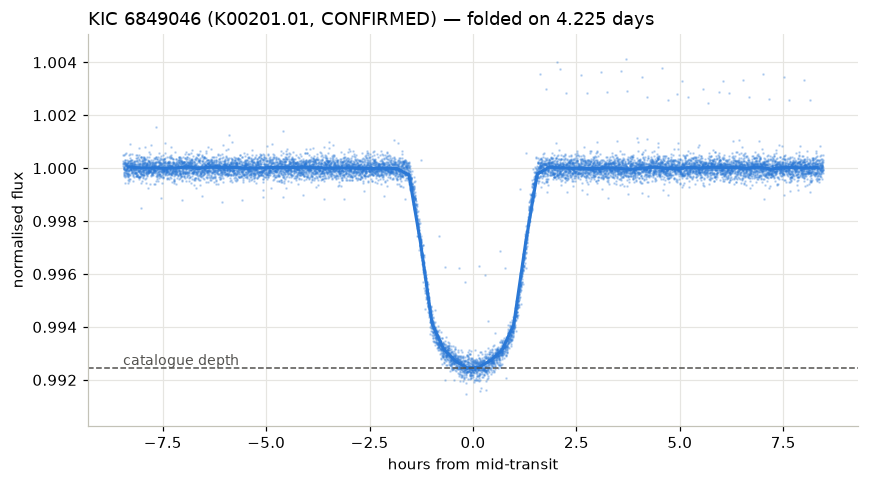

In [4]:
phase_hours = ((lc.time - t0 + 0.5 * P) % P - 0.5 * P) * 24
near = np.abs(phase_hours) < 3 * koi["koi_duration"]   # look at ±3 transit-durations

ph, fl = phase_hours[near], lc.flux[near]
bins = pd.cut(ph, 60)   # 60 equal-width time bins
binned = pd.DataFrame({"ph": ph, "fl": fl}).groupby(bins, observed=True).median()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ph, fl, ".", ms=1.5, color=BLUE, alpha=0.25)
ax.plot(binned.ph, binned.fl, "-", lw=2, color=BLUE)
depth_line = 1 - koi["koi_depth"] / 1e6
ax.axhline(depth_line, color=INK, ls="--", lw=1)
ax.text(ph.min(), depth_line, "catalogue depth", va="bottom", color=INK, fontsize=9)
lo, hi = np.percentile(fl, [0.1, 99.9])
pad = 0.15 * (hi - lo)
ax.set_ylim(min(lo, depth_line) - pad, hi + pad)
ax.set_title(f"KIC {KEPID} ({koi['kepoi_name']}, {koi['koi_disposition']}) — folded on {P:.3f} days", loc="left")
ax.set_xlabel("hours from mid-transit")
ax.set_ylabel("normalised flux")
ax.grid(True)
fig.tight_layout()
fig.savefig(f"../results/folded_{KEPID}.png", dpi=150)
plt.show()

## Does it look right?

- **Plot 1:** the dots sit around 1.0, with gaps between quarters and no wild jumps.
- **Plot 2:** dips line up with the dashed lines.
- **Plot 3:** one clear dip at 0 hours, with its bottom near the "catalogue depth" line.

If all three look right, the download works and you can run the full download.